# Escenarios, ponderaciones y la no linealidad de la PCE

**Pregunta:** ¿Por qué la PCE ponderada por probabilidad de tres escenarios macroeconómicos es mayor que la PCE del escenario promedio, en cuánto en una cartera real, y cuánto del resultado depende de las ponderaciones que elige el banco?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 y 02 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- escribir la PD a un punto del tiempo como función de un factor sistemático y convertir entre una tasa de incumplimiento y el factor que implica;
- mostrar con números por qué la PD ponderada por probabilidad no es la PD del escenario promedio, y por qué un escenario "base" en $z = 0$ es la mediana y no la media;
- verificar la integración de Gauss-Hermite sobre el factor y decir cuántos nodos necesita la identidad del motor;
- ponderar la PCE de tres escenarios por etapa y leer la sensibilidad a las ponderaciones como una derivada lineal exacta mientras la clasificación está congelada;
- distinguir los dos índices de no linealidad (el de nivel de PD y el de nivel de PCE) y medir qué agrega la reclasificación cuando se mueven las ponderaciones.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo"}
SCENARIO = {"baseline": "base", "adverse": "adverso", "severely-adverse": "severamente adverso"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C06 a la fecha de reporte 2008-12-31 (préstamos 7(a) de la SBA, Obras del Gobierno de EE. UU., clase de licencia `mirror-allowed`; los escenarios macroeconómicos son formas de las trayectorias de la prueba de estrés 2026 de la Reserva Federal, mirror-allowed). Se lee un archivo, `data/derived/C06/rd-2008-12.json`:

- `outputs.scenarios`: tres escenarios con su ponderación y su factor sistemático medio $z$;
- `outputs.ecl_by_scenario`: la PCE de cada escenario y etapa, con las etapas fijas en la asignación ponderada;
- `outputs.weight_grid`: quince vectores de ponderaciones en una grilla de paso 0,25, con la PCE **con las etapas congeladas** y la PCE **con las etapas recalculadas** con esas ponderaciones;
- `outputs.non_linearity`: la comparación, a nivel de PD y a nivel de PCE, de la medida ponderada con la trayectoria media, y la curva de la PD condicional contra $z$.

La celda siguiente carga el artefacto e imprime los escenarios, las ponderaciones y las versiones del motor.

In [2]:
# Cargar el artefacto de la fecha de reporte y listar sus escenarios con sus ponderaciones y factores
from riskvalidation.provisions import ecl as ecl_engine, term_structure as tsm
from riskvalidation.validation import ifrs9

LANG = "es"
ROOT = Path("../../..").resolve()
case = json.loads((ROOT / "data" / "derived" / "C06" / "rd-2008-12.json").read_text(encoding="utf-8"))
out = case["outputs"]
print("motor que calculó el artefacto:", case["provenance"]["riskvalidation_version"])
print("motor instalado ahora:", md.version("riskvalidation"))
for s in out["scenarios"]:
    print(f"{SCENARIO[s['id']]:20s} | ponderación {s['weight']:.2f} | factor medio z {s['z_mean']:.4f}")
    print("   ", s["label"][LANG])

motor que calculó el artefacto: 1.0.1
motor instalado ahora: 1.0.1
base                 | ponderación 0.60 | factor medio z -1.4801
    Base (forma Fed 2026)
adverso              | ponderación 0.30 | factor medio z -1.3735
    Adverso (punto medio de las formas Fed, propio de Contraste)
severamente adverso  | ponderación 0.10 | factor medio z -1.3478
    Severamente adverso (forma Fed 2026)


## Método

IFRS 9 pide un monto insesgado y ponderado por probabilidad (5.5.17(a)), construido con más de un escenario cuando la pérdida no es lineal en la trayectoria macroeconómica (B5.5.41 y B5.5.42; GPPC 2016, sección 2.8.1.2). Tres resultados sostienen este cuaderno.

**1. La PD condicional.** En el modelo de un factor de la fórmula IRB (BCBS 2005, sección 4.2; Gordy 2003), un deudor incumple cuando su retorno de activos, $\sqrt{\rho}\,Z + \sqrt{1-\rho}\,\varepsilon$, cae bajo $\Phi^{-1}(PD^{\mathrm{TTC}})$, con $Z$ y $\varepsilon$ normales estándar e independientes. La PD dado el factor sistemático $z$ es

$$PD^{\mathrm{PIT}}(z) = \Phi\!\left(\frac{\Phi^{-1}(PD^{\mathrm{TTC}}) - \sqrt{\rho}\,z}{\sqrt{1-\rho}}\right), \qquad \mathbb{E}_Z\bigl[PD^{\mathrm{PIT}}(Z)\bigr] = PD^{\mathrm{TTC}}$$

y su inversa da el factor implicado por una tasa de incumplimiento observada $DR$: $z = \bigl(\Phi^{-1}(PD^{\mathrm{TTC}}) - \sqrt{1-\rho}\,\Phi^{-1}(DR)\bigr)/\sqrt{\rho}$. Un $z$ negativo es un mal año.

**2. La medida ponderada y su no linealidad.**

$$\mathrm{PCE} = \sum_s w_s\,\mathrm{PCE}_s, \quad w_s \ge 0, \;\sum_s w_s = 1, \qquad \mathrm{NL} = \frac{\mathrm{PCE}_{\mathrm{ponderada}}}{\mathrm{PCE}(\text{trayectoria media})} - 1$$

Como $PD^{\mathrm{PIT}}$ es convexa en $z$ en el rango usual, la desigualdad de Jensen da $\mathbb{E}[PD(Z)] \ge PD(\mathbb{E}[Z])$: la medida ponderada es al menos la medida en el escenario promedio. El BCE (2024) critica los ajustes macro construidos sobre la trayectoria media porque ignoran esta no linealidad y subestiman el impacto medio.

**3. La sensibilidad a las ponderaciones.** La PCE es lineal en las ponderaciones, así que mover ponderación desde un escenario de referencia hacia $s$ la cambia en $\partial\,\mathrm{PCE}/\partial w_s = \mathrm{PCE}_s - \mathrm{PCE}_{\mathrm{ref}}$ (BCBS d350, párrafo 36(a)). Las etapas no son lineales en las ponderaciones cuando la prueba de SICR usa PD ponderadas (GPPC 2016, 2.7.2.10), así que la grilla versionada del motor reporta ambas versiones: etapas congeladas (exactamente lineal) y etapas recalculadas.

Las PCE de un solo escenario al 100 por ciento son sensibilidades, nunca la medida de IFRS 9.

### Paso 1: la curva de PD condicional de la cartera y su inversa

El artefacto entrega la $PD^{\mathrm{TTC}}$ y la $\rho$ de la cartera (`non_linearity.parameters`) y los siete factores $z = -3, \dots, 3$ en que informa la curva. La celda evalúa `ttc_to_pit` en esos factores y luego aplica `implied_z`, la inversa, a las tasas de incumplimiento que devolvió la curva: los factores deben volver. La figura dibuja la curva en un eje logarítmico con los siete puntos y la $PD^{\mathrm{TTC}}$ incondicional.

PD_TTC: 0.016389 | rho: 0.12
z = -3 | PD(z): 0.121428 | factor recuperado: -3.0
z = -2 | PD(z): 0.062128 | factor recuperado: -2.0
z = -1 | PD(z): 0.028298 | factor recuperado: -1.0
z = +0 | PD(z): 0.011432 | factor recuperado: 0.0
z = +1 | PD(z): 0.004085 | factor recuperado: 1.0
z = +2 | PD(z): 0.001288 | factor recuperado: 2.0
z = +3 | PD(z): 0.000358 | factor recuperado: 3.0


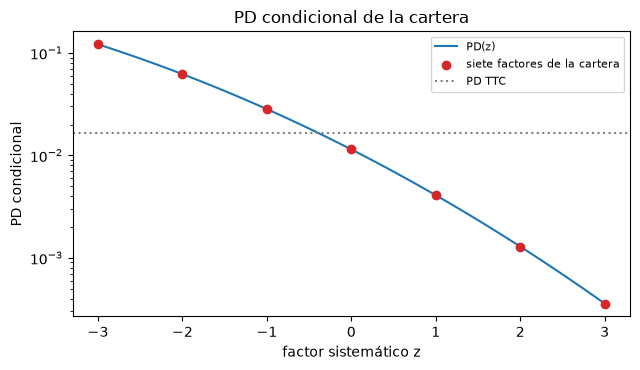

In [3]:
# Evaluar la curva de PD condicional de la cartera en siete factores y recuperar los factores con la inversa
nl = out["non_linearity"]
pd_ttc, rho = nl["parameters"]["pd_ttc"], nl["parameters"]["rho"]
z_grid = np.array([p["z"] for p in nl["z_curve"]])
curve = tsm.ttc_to_pit(np.full(z_grid.size, pd_ttc), rho, z_grid)
recovered = tsm.implied_z(curve, pd_ttc, rho)
print("PD_TTC:", round(pd_ttc, 6), "| rho:", rho)
for z_, p_, r_ in zip(z_grid, curve, recovered):
    print("z =", f"{z_:+.0f}", "| PD(z):", round(float(p_), 6), "| factor recuperado:", round(float(r_), 6))

zz = np.linspace(-3.0, 3.0, 121)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(zz, tsm.ttc_to_pit(np.full(zz.size, pd_ttc), rho, zz), color="tab:blue", label="PD(z)")
ax.scatter(z_grid, curve, color="tab:red", zorder=3, label="siete factores de la cartera")
ax.axhline(pd_ttc, color="grey", linestyle=":", label="PD TTC")
ax.set_yscale("log")
ax.set_xlabel("factor sistemático z")
ax.set_ylabel("PD condicional")
ax.set_title("PD condicional de la cartera")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La PD condicional cae de 12,14% en $z = -3$ a 0,04% en $z = +3$, un factor de más de 300 a lo largo de seis unidades del factor, y la inversa devuelve los siete factores exactamente. La curva es empinada y se curva: su pendiente es mayor en el lado malo, donde $z$ es negativo. Un año malo sube la tasa de incumplimiento mucho más de lo que un año bueno la baja, y esa es la forma que hace del promedio de los escenarios el lugar equivocado para evaluar la pérdida.

### Paso 2: un ejemplo trabajado de la no linealidad, y la trampa de la mediana

El ejemplo de referencia del motor viene de la ilustración del dossier: $PD^{\mathrm{TTC}} = 2\%$, $\rho = 0{,}12$, tres escenarios en $z = +1$ (alza, ponderación 0,25), $z = 0$ (base, 0,50) y $z = -2$ (baja, 0,25). Son **insumos de la lección**, elegidos para el ejemplo, no datos de Contraste. La celda calcula la PD condicional de cada escenario, la PD ponderada con `weighted_pit_pd`, la PD en el factor medio ponderado y la `nonlinearity_test` propia del motor. La figura pone todo sobre la curva.

PD condicional por escenario, porcentaje: [0.526 1.429 7.342]
PD ponderada, porcentaje: 2.681 | factor medio ponderado: -0.25
PD en ese factor, porcentaje: 1.8 | razón: 1.49
prueba del motor: índice: 0.4898 | luz: verde
PD en z = 0 (la mediana), porcentaje: 1.429


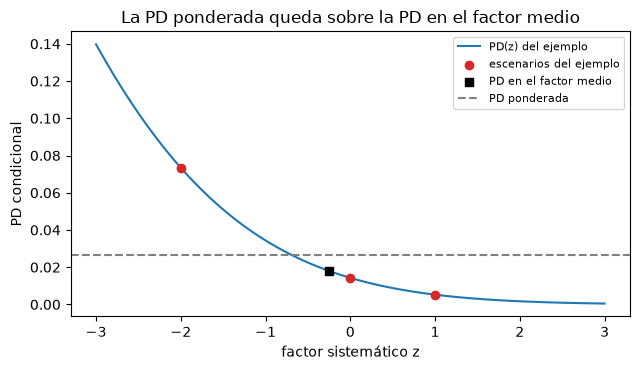

In [4]:
# El ejemplo de referencia: tres escenarios, la PD ponderada, la PD en el factor medio y la prueba del motor
EX_PD, EX_RHO = 0.02, 0.12  # inputs of the lesson
ex_z = np.array([1.0, 0.0, -2.0])
ex_w = np.array([0.25, 0.50, 0.25])
per_scenario = tsm.ttc_to_pit(EX_PD, EX_RHO, ex_z)
weighted = float(tsm.weighted_pit_pd(EX_PD, EX_RHO, ex_z, ex_w))
mean_z = float(np.sum(ex_w * ex_z))
at_mean = float(tsm.ttc_to_pit(EX_PD, EX_RHO, mean_z))
test = ifrs9.nonlinearity_test(EX_PD, EX_RHO, ex_z, ex_w, model_id="lesson")
print("PD condicional por escenario, porcentaje:", np.round(100 * per_scenario, 3))
print("PD ponderada, porcentaje:", round(100 * weighted, 3), "| factor medio ponderado:", mean_z)
print("PD en ese factor, porcentaje:", round(100 * at_mean, 3), "| razón:", round(weighted / at_mean, 2))
print("prueba del motor: índice:", round(test.metric, 4), "| luz:", LIGHT[test.light.value])
print("PD en z = 0 (la mediana), porcentaje:", round(100 * float(per_scenario[1]), 3))

zz = np.linspace(-3.0, 3.0, 121)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(zz, tsm.ttc_to_pit(np.full(zz.size, EX_PD), EX_RHO, zz), color="tab:blue", label="PD(z) del ejemplo")
ax.scatter(ex_z, per_scenario, color="tab:red", zorder=3, label="escenarios del ejemplo")
ax.scatter([mean_z], [at_mean], color="black", marker="s", zorder=3, label="PD en el factor medio")
ax.axhline(weighted, color="grey", linestyle="--", label="PD ponderada")
ax.set_xlabel("factor sistemático z")
ax.set_ylabel("PD condicional")
ax.set_title("La PD ponderada queda sobre la PD en el factor medio")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La PD ponderada es 2,681% y la PD en el escenario promedio, $z = -0{,}25$, es 1,800%: ignorar la no linealidad subestima la PD en un tercio, una razón de 1,49, y la tasa de pérdida con una pérdida dado el incumplimiento de 40% sería 1,07% ponderada frente a 0,72% en la media. El escenario base en $z = 0$ da 1,429%, que es la mediana y no la media, y queda bajo el 2% incondicional. Un banco que llama caso base al escenario mediano y se detiene ahí informa menos que la medida ponderada que pide IFRS 9.

### Paso 3: la verificación de Gauss-Hermite

La identidad $\mathbb{E}_Z[PD^{\mathrm{PIT}}(Z)] = PD^{\mathrm{TTC}}$ es la verificación cruzada de la no linealidad del motor. `gauss_hermite_pit_pd` integra la PD condicional sobre la normal estándar con nodos de Gauss-Hermite de probabilistas. La celda sube el número de nodos de 2 a 64 y dibuja el error frente a $PD^{\mathrm{TTC}}$, con piso en $10^{-16}$, el redondeo de la aritmética.

nodos   2 | error frente a PD_TTC: 2e-04
nodos   4 | error frente a PD_TTC: 5e-07
nodos   8 | error frente a PD_TTC: 9e-12
nodos  16 | error frente a PD_TTC: 1e-16
nodos  32 | error frente a PD_TTC: 1e-16
nodos  64 | error frente a PD_TTC: 1e-16


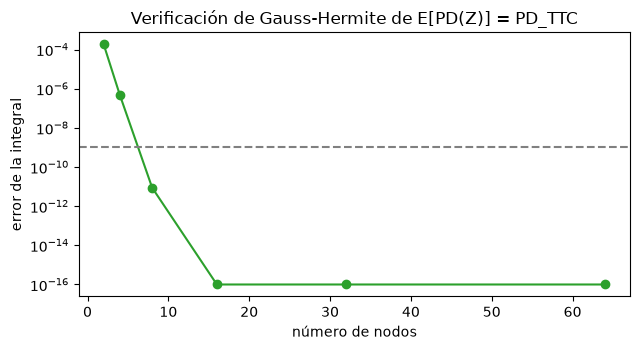

In [5]:
# El error de la integral de Gauss-Hermite frente a PD_TTC al crecer los nodos, con piso en 1e-16
nodes = (2, 4, 8, 16, 32, 64)
integrals = [tsm.gauss_hermite_pit_pd(EX_PD, EX_RHO, n) for n in nodes]
errors = [max(abs(value - EX_PD), 1e-16) for value in integrals]
for n, error in zip(nodes, errors):
    print("nodos", f"{n:3d}", "| error frente a PD_TTC:", f"{error:.0e}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.semilogy(nodes, errors, marker="o", color="tab:green")
ax.axhline(1e-9, color="grey", linestyle="--")
ax.set_xlabel("número de nodos")
ax.set_ylabel("error de la integral")
ax.set_title("Verificación de Gauss-Hermite de E[PD(Z)] = PD_TTC")
fig.tight_layout()
plt.show()

El error cae de 2e-04 con dos nodos a 5e-07 con cuatro y 9e-12 con ocho, y desde 16 nodos queda en el piso de la aritmética. La línea discontinua marca $10^{-9}$, la tolerancia de la prueba del motor, que ocho nodos ya cumplen. La integral es entonces una verificación suficientemente exacta de que la PD condicional, promediada sobre el factor, devuelve la PD a través del ciclo: la curva del paso 1 es un mapa calibrado desde el factor hacia la tasa de incumplimiento.

### Paso 4: las mismas dos comparaciones sobre la cartera versionada

De vuelta en C06. El artefacto entrega los tres factores y ponderaciones de escenario que usó (`scenario_points`). La celda calcula la PD ponderada y la PD en el factor medio ponderado de la cartera con `weighted_pit_pd` y `ttc_to_pit`, y el índice a nivel de PD con `non_linearity_index`. Luego lee el **nivel de PCE**: la PCE versionada ponderada sobre los escenarios y la PCE versionada en la trayectoria media pasan por la misma función, y la figura pone los dos índices lado a lado.

PD ponderada de la cartera: 0.04045198
PD en el factor medio de la cartera: 0.04041987
índice a nivel de PD: 0.000794 | índice a nivel de PCE: 0.02121
el índice a nivel de PCE sobre el índice a nivel de PD: 26.7


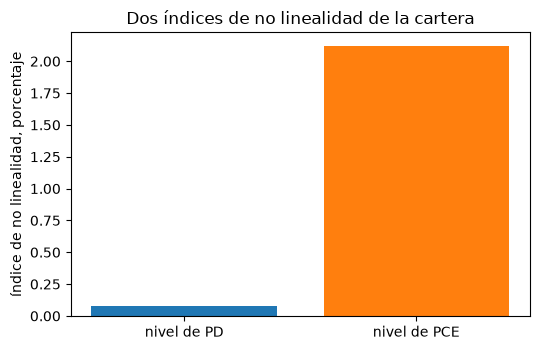

In [6]:
# Calcular la PD ponderada y la PD en el factor medio de la cartera, y los dos índices
points = nl["scenario_points"]
z_book = np.array([p["z"] for p in points])
w_book = np.array([p["weight"] for p in points])
pd_weighted = float(tsm.weighted_pit_pd(pd_ttc, rho, z_book, w_book))
pd_mean = float(tsm.ttc_to_pit(pd_ttc, rho, float(np.sum(w_book * z_book))))
pd_index = ecl_engine.non_linearity_index(pd_weighted, pd_mean)
ecl_index = ecl_engine.non_linearity_index(nl["ecl_weighted"], nl["ecl_at_mean_path"])
print("PD ponderada de la cartera:", round(pd_weighted, 8))
print("PD en el factor medio de la cartera:", round(pd_mean, 8))
print("índice a nivel de PD:", round(pd_index, 6), "| índice a nivel de PCE:", round(ecl_index, 6))
print("el índice a nivel de PCE sobre el índice a nivel de PD:", round(ecl_index / pd_index, 1))

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(["nivel de PD", "nivel de PCE"], [100 * pd_index, 100 * ecl_index], color=["tab:blue", "tab:orange"])
ax.set_ylabel("índice de no linealidad, porcentaje")
ax.set_title("Dos índices de no linealidad de la cartera")
fig.tight_layout()
plt.show()

A nivel de PD los tres escenarios de la cartera están cerca entre sí sobre la curva (factores entre -1,48 y -1,35), así que la PD ponderada de 0,04045 supera a la PD en el factor medio en solo 0,08%. A nivel de PCE el índice es 0,0212, 2,12%, unas 27 veces mayor. La PCE es más no lineal que la PD porque la clasificación en etapas se mueve con el escenario: un escenario peor pone más préstamos en la Etapa 2, donde la PCE de vida completa es varias veces mayor. Un validador que probara solo el nivel de PD aprobaría una medida cuya no linealidad real está un nivel más arriba.

### Paso 5: ponderar las PCE de los escenarios por etapa

`ecl_by_scenario` guarda la PCE de cada escenario por etapa, con las etapas fijas en la asignación ponderada. Apilamos los tres escenarios en un arreglo de forma (escenarios, etapas) y lo ponderamos con `probability_weighted_ecl`, que devuelve la reserva por etapa. Sumar las filas da la PCE al 100% de cada escenario, una sensibilidad y nunca la medida de IFRS 9. La figura contrasta los tres totales de un solo escenario con el total ponderado y la PCE en la trayectoria media.

Etapa 1 | PCE ponderada, USD millones: 798.078
Etapa 2 | PCE ponderada, USD millones: 68.929
Etapa 3 | PCE ponderada, USD millones: 0.0
base                 PCE al 100 por ciento del escenario, USD millones:   897.476
adverso              PCE al 100 por ciento del escenario, USD millones:   825.460
severamente adverso  PCE al 100 por ciento del escenario, USD millones:   808.827
total ponderado, USD millones: 867.007
PCE en la trayectoria media, USD millones: 848.999


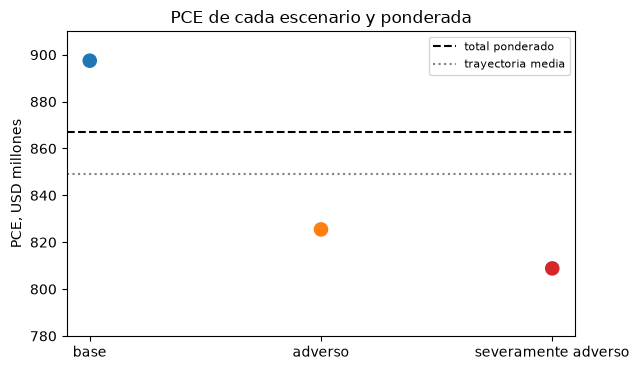

In [7]:
# Ponderar la PCE de los tres escenarios por etapa y comparar los escenarios con el total ponderado
ids = [s["id"] for s in out["scenarios"]]
weights = np.array([s["weight"] for s in out["scenarios"]])
stages = ("stage1", "stage2", "stage3")
by = {(r["scenario_id"], r["stage"]): r["ecl"] for r in out["ecl_by_scenario"]["rows"]}
matrix = np.array([[by[(sid, st)] for st in stages] for sid in ids])
weighted_by_stage = ecl_engine.probability_weighted_ecl(matrix, weights)
single = matrix.sum(axis=1)
total = float(weighted_by_stage.sum())
for k, value in enumerate(weighted_by_stage, start=1):
    print("Etapa", k, "| PCE ponderada, USD millones:", round(float(value) / 1e6, 3))
for sid, value in zip(ids, single):
    print(f"{SCENARIO[sid]:20s} PCE al 100 por ciento del escenario, USD millones: {value / 1e6:9.3f}")
print("total ponderado, USD millones:", round(total / 1e6, 3))
print("PCE en la trayectoria media, USD millones:", round(nl["ecl_at_mean_path"] / 1e6, 3))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.scatter([SCENARIO[s] for s in ids], single / 1e6, s=90, color=["tab:blue", "tab:orange", "tab:red"], zorder=3)
ax.axhline(total / 1e6, color="black", linestyle="--", label="total ponderado")
ax.axhline(nl["ecl_at_mean_path"] / 1e6, color="grey", linestyle=":", label="trayectoria media")
ax.set_ylim(780, 910)
ax.set_ylabel("PCE, USD millones")
ax.set_title("PCE de cada escenario y ponderada")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La reserva ponderada es 867,007 millones de USD, casi toda en la Etapa 1 (798,078 millones) con 68,929 millones en la Etapa 2, y queda sobre los 848,999 millones de la trayectoria media, como dice la no linealidad que debe ocurrir. La figura muestra otra cosa que un validador lee primero: el escenario severamente adverso produce una PCE menor, 808,827 millones, que el escenario base, 897,476 millones. Es el hallazgo versionado `F-SCENARIO-ORDER`, un signo equivocado en las sensibilidades macro de la tasa de riesgo en esta fecha, y toda sensibilidad construida sobre el orden de los escenarios lo hereda.

### Paso 6: la sensibilidad a las ponderaciones, lineal cuando la clasificación está congelada

Con las etapas fijas la PCE es lineal en las ponderaciones, de modo que `weight_sensitivity` devuelve el cambio exacto de mover toda la ponderación a cada escenario desde una referencia, $\mathrm{ECL}_s - \mathrm{ECL}_{\mathrm{ref}}$. El artefacto guarda quince vectores de ponderaciones en una grilla de paso 0,25, con la PCE recalculada tras reclasificar con esas ponderaciones. La celda pondera los totales de un solo escenario en cada uno de ellos con `probability_weighted_ecl`, que es la PCE con clasificación congelada, y la pone junto a la recalculada versionada a lo largo de un borde de la grilla.

vectores de ponderaciones en la grilla: 15
cambio de mover toda la ponderación desde el escenario base a cada escenario, USD millones:
[  0.    -72.016 -88.65 ]
PCE recalculada menos congelada en la grilla, USD millones, menor y mayor:
-15.235 2.089
proporción de la Etapa 2, recalculada, menor y mayor:
0.00779 0.01236


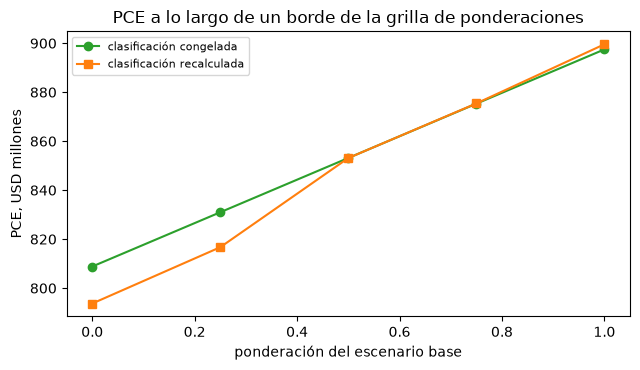

In [8]:
# Ponderar los totales de un solo escenario en la grilla de ponderaciones y leer la sensibilidad
grid = out["weight_grid"]["points"]
frozen = np.array([float(ecl_engine.probability_weighted_ecl(single, np.array(p["weights"]))) for p in grid])
sens = ecl_engine.weight_sensitivity(single, 0)
gap = np.array([p["ecl_recomputed"] - p["ecl_frozen"] for p in grid]) / 1e6
shares = [p["stage2_ratio_recomputed"] for p in grid]
print("vectores de ponderaciones en la grilla:", len(grid))
print("cambio de mover toda la ponderación desde el escenario base a cada escenario, USD millones:")
print(np.round(sens / 1e6, 3))
print("PCE recalculada menos congelada en la grilla, USD millones, menor y mayor:")
print(round(float(gap.min()), 3), round(float(gap.max()), 3))
print("proporción de la Etapa 2, recalculada, menor y mayor:")
print(round(min(shares), 5), round(max(shares), 5))

edge = [k for k, p in enumerate(grid) if p["weights"][1] == 0.0]
edge = [edge[j] for j in np.argsort([grid[k]["weights"][0] for k in edge])]
xs = [grid[k]["weights"][0] for k in edge]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(xs, [frozen[k] / 1e6 for k in edge], marker="o", color="tab:green", label="clasificación congelada")
recomputed = [grid[k]["ecl_recomputed"] / 1e6 for k in edge]
ax.plot(xs, recomputed, marker="s", color="tab:orange", label="clasificación recalculada")
ax.set_xlabel("ponderación del escenario base")
ax.set_ylabel("PCE, USD millones")
ax.set_title("PCE a lo largo de un borde de la grilla de ponderaciones")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Mover toda la ponderación del escenario base al adverso cambia la PCE congelada en -72,016 millones y al severamente adverso en -88,650 millones, ambos negativos por el orden de los escenarios hallado en el paso 5. Las dos líneas de la figura son paralelas pero no iguales: reclasificar con las nuevas ponderaciones cambia la PCE entre -15,235 y +2,089 millones respecto del valor congelado, y mueve la proporción de la Etapa 2 entre 0,78% y 1,24%. Una lectura lineal de las ponderaciones es exacta solo mientras las etapas están quietas, y la parte que omite es la parte que el validador debe mostrar.

## Resultados

**Respuesta:** La PCE ponderada por probabilidad de la cartera es 867,007 millones de USD frente a 848,999 millones en la trayectoria promedio, un exceso de 2,12%, un índice de 0,0212 que es unas 27 veces el 0,0008 que muestra su PD sola, porque la PD condicional es convexa en el factor macroeconómico y la clasificación en etapas se mueve con el escenario; el resultado depende además de las ponderaciones, ya que mover todas desde el escenario base al adverso cambia la PCE en -72,016 millones, mientras que reclasificar agrega entre -15,235 y 2,089 millones que una lectura lineal omite.

- **La curva y su inversa cierran.** La PD condicional de la cartera va de 12,14% en $z = -3$ a 0,04% en $z = +3$, y `implied_z` recupera los siete factores desde las tasas de incumplimiento que devolvió la curva.
- **La PD ponderada no es la PD del escenario promedio.** En el ejemplo de la lección la PD ponderada es 2,681% y la PD en el factor promedio es 1,800%, una razón de 1,49; el escenario base en $z = 0$ da 1,429%, la mediana, bajo el 2% incondicional.
- **La identidad necesita pocos nodos.** El error de Gauss-Hermite frente a $PD^{\mathrm{TTC}}$ es 9e-12 con ocho nodos y está en el piso de la aritmética desde dieciséis, así que la tolerancia del motor de $10^{-9}$ se cumple con holgura.
- **El nivel de PCE es donde está la no linealidad.** En la cartera el índice a nivel de PD es 0,0008 y el índice a nivel de PCE es 0,0212, porque un escenario peor también pone más préstamos en la Etapa 2.
- **Los escenarios versionados no están ordenados por severidad.** El escenario severamente adverso da 808,827 millones y el base 897,476 millones (hallazgo `F-SCENARIO-ORDER`), de modo que las sensibilidades a las ponderaciones son negativas, -72,016 y -88,650 millones, y un validador lo lee primero como un hallazgo del modelo.
- **La clasificación congelada y la recalculada difieren.** A lo largo de la grilla de ponderaciones la PCE recalculada difiere de la congelada entre -15,235 y 2,089 millones y la proporción de la Etapa 2 se mueve entre 0,78% y 1,24%.

Lo que este cuaderno no muestra: los factores de escenario de la cartera están muy juntos (entre -1,48 y -1,35), así que la no linealidad a nivel de PD de la cartera es pequeña por construcción. Los tres escenarios son formas de las trayectorias 2026 de la Reserva Federal, no pronósticos de 2008. El signo equivocado de las sensibilidades macro es un hallazgo que corregir en el modelo, y este cuaderno solo mide su consecuencia.

## Resumen

- La PD condicional es una función convexa del factor sistemático en el rango habitual, de modo que la PD ponderada por probabilidad es al menos la PD del escenario promedio; el motor enuncia la identidad, su inversa y una verificación de Gauss-Hermite.
- Un escenario base en $z = 0$ da la PD mediana, no la media; el ejemplo muestra 1,429% frente a 2,000%.
- La PCE se pondera escenario por escenario con `probability_weighted_ecl`, y los índices a nivel de PCE y de PD son magnitudes distintas: el primero es mayor porque la clasificación en etapas se mueve con el escenario.
- Con la clasificación congelada la sensibilidad a las ponderaciones es exactamente $\mathrm{ECL}_s - \mathrm{ECL}_{\mathrm{ref}}$; reclasificar con las nuevas ponderaciones agrega una parte que una lectura lineal omite.
- Los escenarios versionados no están ordenados por severidad a esta fecha (hallazgo `F-SCENARIO-ORDER`); un validador lo lee como un hallazgo del modelo antes de leer cualquier sensibilidad.

**Qué probar después.** Cambia `EX_RHO` a 0,04 y a 0,24 y observa la razón entre la PD ponderada y la PD en el factor medio; cambia `ex_w` a ponderaciones iguales. Luego sigue con el cuaderno 04, que convierte estas PCE en una reserva y concilia su movimiento.

## Referencias

- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 de junio de 2016, secciones 2.1.1, 2.7.2 y 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), párrafos 36, 50 y 51 y párrafo A26 del anexo. https://www.bis.org/bcbs/publ/d350.htm
- BCBS (2005), An explanatory note on the Basel II IRB risk weight functions, sección 4.2: el modelo de un factor. https://www.bis.org/publications/explanatory-note-basel-ii-irb-risk-weight-functions.pdf
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3), 199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- ECB Banking Supervision (2024), IFRS 9 overlays and model improvements for novel risks, julio de 2024. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.IFRS9novelrisks_202407~5e0eb30b5c.en.pdf